# 01 · Demand and revenue forecasting

**Business question:** how many orders and how much revenue to expect in the coming months (including Black Friday 2026), to plan fabric purchasing, the fulfillment team and the media budget?

**Data:** `tecidos_marts.fct_kpis_diarios` (dbt) with paid orders, revenue and spend per day; `tecidos.estoque_diario` for the demand lost to stockouts.

**Approach**
1. Time-based validation: train up to Apr 14, 2026 and test on the following 6 months (Mother's Day, the June festivals and the whole winter inside the test).
2. Three models: a naive seasonal *baseline*, a SARIMAX dynamic regression (statsmodels) and LightGBM with calendar features.
3. 90-day forecast with an interval (quantile LightGBM).
4. Censored demand: how much demand does not show up in sales because of missing stock.

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
import lightgbm as lgb
import statsmodels.api as sm
import warnings
from utils_nb import sql, configurar_graficos, brl, CORES, COR_REAL, COR_PREVISTO, COR_DESTAQUE

warnings.filterwarnings("ignore")
configurar_graficos()

In [2]:
kpi = sql("SELECT data, pedidos, receita, investimento, investimento_meta, investimento_google, sessoes "
          "FROM tecidos_marts.fct_kpis_diarios ORDER BY data")
kpi["data"] = pd.to_datetime(kpi["data"])
kpi = kpi.set_index("data").asfreq("D").fillna(0)
kpi.tail()

,pedidos,receita,investimento,investimento_meta,investimento_google,sessoes
data,,,,,,
2026-10-09,148,49144.66,4456.93,2691.26,1765.67,5733
2026-10-10,140,39075.62,4670.75,2717.97,1952.78,5603
2026-10-11,138,50870.35,4504.77,2538.36,1966.41,6135
2026-10-12,140,47884.43,4548.39,2607.15,1941.24,6306
2026-10-13,132,44067.68,4655.51,2698.43,1957.08,6996


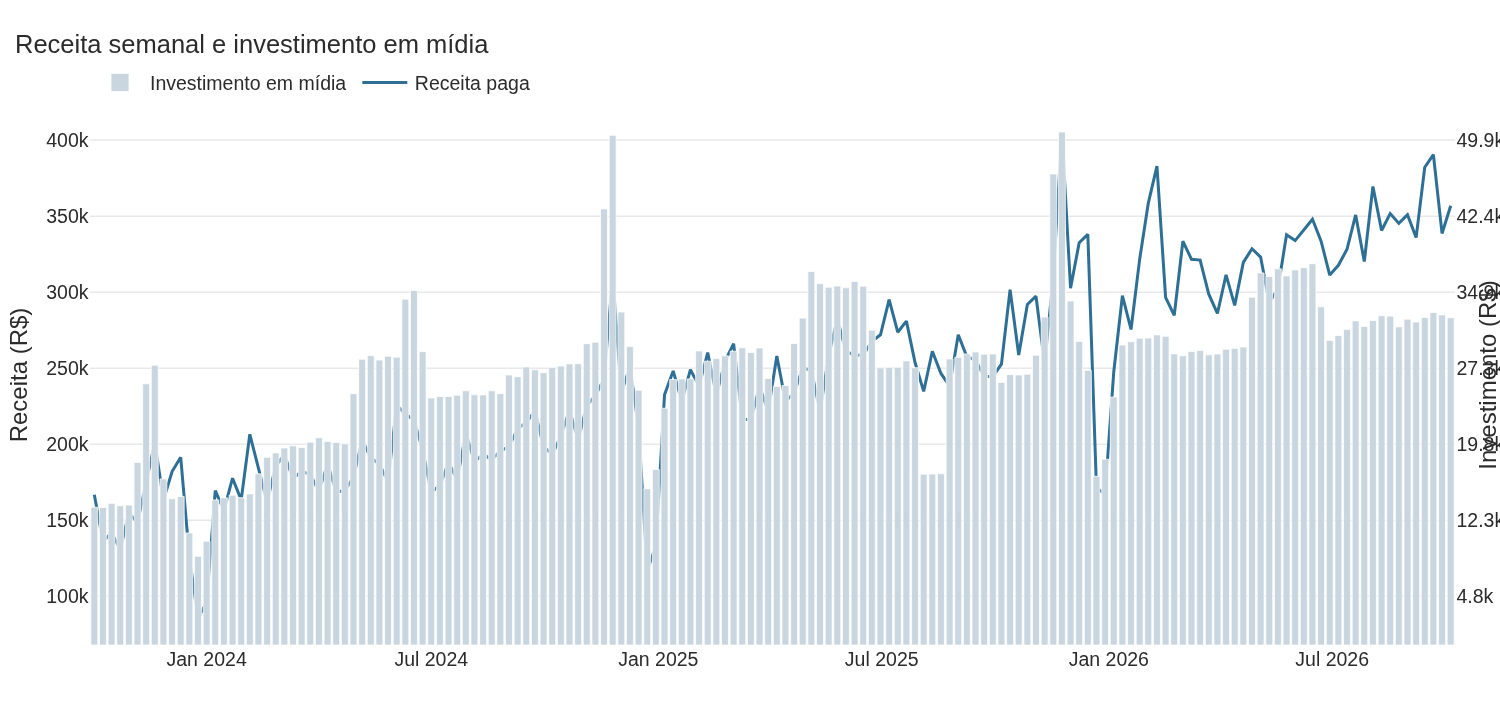

In [3]:
semanal = kpi.resample("W-MON", label="left", closed="left")[["pedidos", "receita", "investimento"]].sum().iloc[1:-1]
fig = go.Figure()
fig.add_bar(x=semanal.index, y=semanal["investimento"], name="Investimento em mídia", marker_color="#c9d6df", yaxis="y2")
fig.add_scatter(x=semanal.index, y=semanal["receita"], name="Receita paga", line=dict(color=COR_REAL, width=2))
fig.update_layout(title="Receita semanal e investimento em mídia",
                  yaxis=dict(title="Receita (R$)"), yaxis2=dict(title="Investimento (R$)", overlaying="y", side="right", showgrid=False))
fig.show()

The series has three visible components: a **growth trend**, **peaks on retail dates** (Black Friday, Consumer Day, Seamstress Day, the June festivals) and a **sharp drop at the end of December**. The day-of-week variation is below:

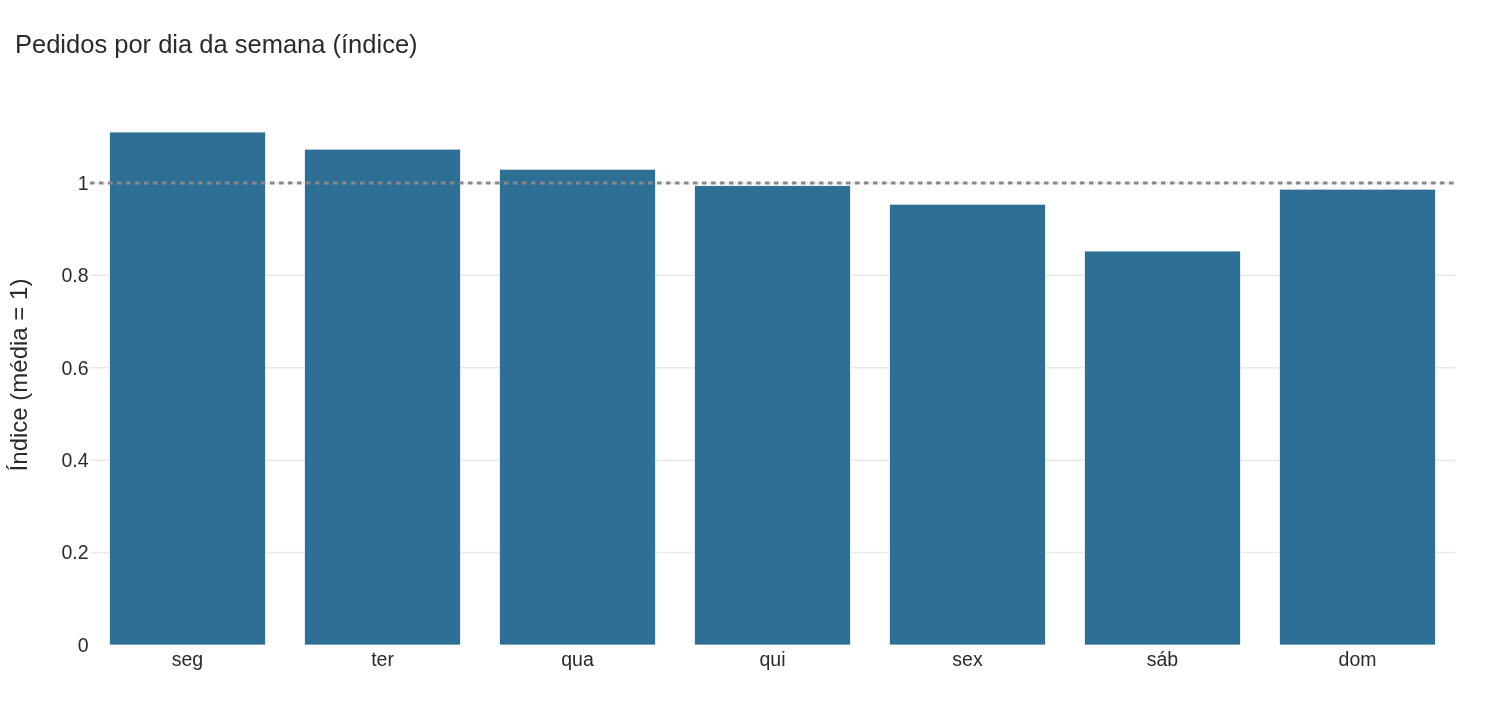

In [4]:
dow = kpi.assign(dia=kpi.index.dayofweek).groupby("dia")["pedidos"].mean()
dow.index = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
fig = px.bar(x=dow.index, y=dow.values / dow.mean(), labels={"x": "", "y": "Índice (média = 1)"},
             title="Pedidos por dia da semana (índice)")
fig.update_traces(marker_color=COR_REAL)
fig.add_hline(y=1, line_dash="dot", line_color="#888")
fig.show()

## Calendar features

Retail dates are public knowledge and enter as features. To forecast 90 days ahead without leakage, **I do not use short lags** (yesterday, last week): only calendar, trend, a yearly lag (364 days) and the planned spend.

In [5]:
BF = pd.to_datetime(["2023-11-24", "2024-11-29", "2025-11-28", "2026-11-27"])
DIA_MAES = pd.to_datetime(["2024-05-12", "2025-05-11", "2026-05-10"])
CARNAVAL = pd.to_datetime(["2024-02-13", "2025-03-04", "2026-02-17"])

def dias_ate(idx, datas):
    d = np.full(len(idx), 999)
    for x in datas:
        dd = (x - idx).days.values
        d = np.where((dd >= -3) & (np.abs(dd) < np.abs(d)), dd, d)
    return d

def calendario(idx, invest=None):
    f = pd.DataFrame(index=idx)
    f["dia_semana"] = idx.dayofweek
    f["mes"] = idx.month
    f["dia_mes"] = idx.day
    f["dia_ano"] = idx.dayofyear
    f["t"] = (idx - pd.Timestamp("2023-10-01")).days
    f["dias_ate_bf"] = dias_ate(idx, BF)
    f["semana_bf"] = ((f["dias_ate_bf"] >= -3) & (f["dias_ate_bf"] <= 10)).astype(int)
    f["dia_bf"] = (f["dias_ate_bf"] == 0).astype(int)                                   # a sexta-feira em si
    f["pos_bf"] = ((f["dias_ate_bf"] >= -3) & (f["dias_ate_bf"] <= -1)).astype(int)    # fim de semana e Cyber Monday
    f["dias_ate_maes"] = dias_ate(idx, DIA_MAES)
    f["dias_ate_carnaval"] = dias_ate(idx, CARNAVAL)
    md_ = idx.month * 100 + idx.day
    f["natal"] = ((md_ >= 1201) & (md_ <= 1218)).astype(int)
    f["fim_de_ano"] = ((md_ >= 1222) | (md_ <= 106)).astype(int)
    f["junina"] = ((md_ >= 501) & (md_ <= 630)).astype(int)
    f["volta_aulas"] = ((md_ >= 115) & (md_ <= 225)).astype(int)
    f["dia_consumidor"] = ((md_ >= 312) & (md_ <= 316)).astype(int)
    f["dia_costureira"] = ((md_ >= 522) & (md_ <= 525)).astype(int)
    f["salario"] = ((idx.day >= 5) & (idx.day <= 10)).astype(int)
    if invest is not None:
        f["investimento"] = invest.reindex(idx).values
    return f

X_all = calendario(kpi.index, kpi["investimento"])
X_all["pedidos_ano_anterior"] = kpi["pedidos"].shift(364).reindex(X_all.index).values
y_all = kpi["pedidos"]
corte = pd.Timestamp("2026-04-14")
treino, teste = X_all.index <= corte, X_all.index > corte
print(f"treino: {treino.sum()} dias | teste: {teste.sum()} dias ({X_all.index[teste][0].date()} a {X_all.index[-1].date()})")

treino: 927 dias | teste: 182 dias (2026-04-15 a 2026-10-13)


## Models

In [6]:
def wape(y, p):
    return np.abs(y - p).sum() / y.sum()

resultados = {}
y_te = y_all[teste]

# 1) Baseline: mesmo dia da semana do ano anterior x crescimento observado nos 90 dias antes do corte
cresc = y_all[corte - pd.Timedelta(days=89):corte].sum() / y_all[corte - pd.Timedelta(days=89 + 364):corte - pd.Timedelta(days=364)].sum()
prev_base = y_all.shift(364)[teste] * cresc
resultados["Baseline sazonal (ano anterior x crescimento)"] = prev_base

# 2) SARIMAX no log, com sazonalidade semanal e exógenas de calendário + investimento
exog_cols = ["semana_bf", "dia_bf", "pos_bf", "natal", "fim_de_ano", "junina", "volta_aulas", "dia_consumidor", "dia_costureira", "salario"]
def exogenas(X):
    ex = X[exog_cols].copy()
    ex["log_invest"] = np.log1p(X["investimento"])
    for k in (1, 2):  # sazonalidade anual por Fourier
        ex[f"sin{k}"] = np.sin(2 * np.pi * k * X["dia_ano"] / 365.25)
        ex[f"cos{k}"] = np.cos(2 * np.pi * k * X["dia_ano"] / 365.25)
    ex["t"] = X["t"] / 365
    return ex

ex = exogenas(X_all)
SARIMAX_KW = dict(order=(1, 0, 1), seasonal_order=(1, 0, 1, 7), trend="c")
mod = sm.tsa.SARIMAX(np.log1p(y_all[treino].values), exog=ex[treino].values, **SARIMAX_KW).fit(disp=False, maxiter=200)
prev_sarimax = pd.Series(np.expm1(mod.forecast(int(teste.sum()), exog=ex[teste].values)), index=y_te.index)
resultados["SARIMAX (log) + calendário"] = prev_sarimax

# 3) LightGBM
feat = [c for c in X_all.columns]
params = dict(objective="poisson", learning_rate=0.03, num_leaves=15, min_data_in_leaf=10, feature_fraction=0.9,
              bagging_fraction=0.9, bagging_freq=1, lambda_l2=1.0, verbose=-1, seed=7)
m_lgb = lgb.train(params, lgb.Dataset(X_all[treino][feat], y_all[treino]), num_boost_round=900)
prev_lgb = pd.Series(m_lgb.predict(X_all[teste][feat]), index=y_te.index)
resultados["LightGBM (Poisson) + calendário"] = prev_lgb

tabela = pd.DataFrame({
    nome: {"WAPE diário": wape(y_te, p), "Erro no total do período": p.sum() / y_te.sum() - 1,
           "WAPE semanal": wape(y_te.resample("W").sum(), p.resample("W").sum())}
    for nome, p in resultados.items()}).T
tabela.style.format("{:.1%}")

,WAPE diário,Erro no total do período,WAPE semanal
Baseline sazonal (ano anterior x crescimento),13.4%,0.4%,6.9%
SARIMAX (log) + calendário,9.6%,1.8%,4.7%
LightGBM (Poisson) + calendário,15.4%,-14.1%,14.2%


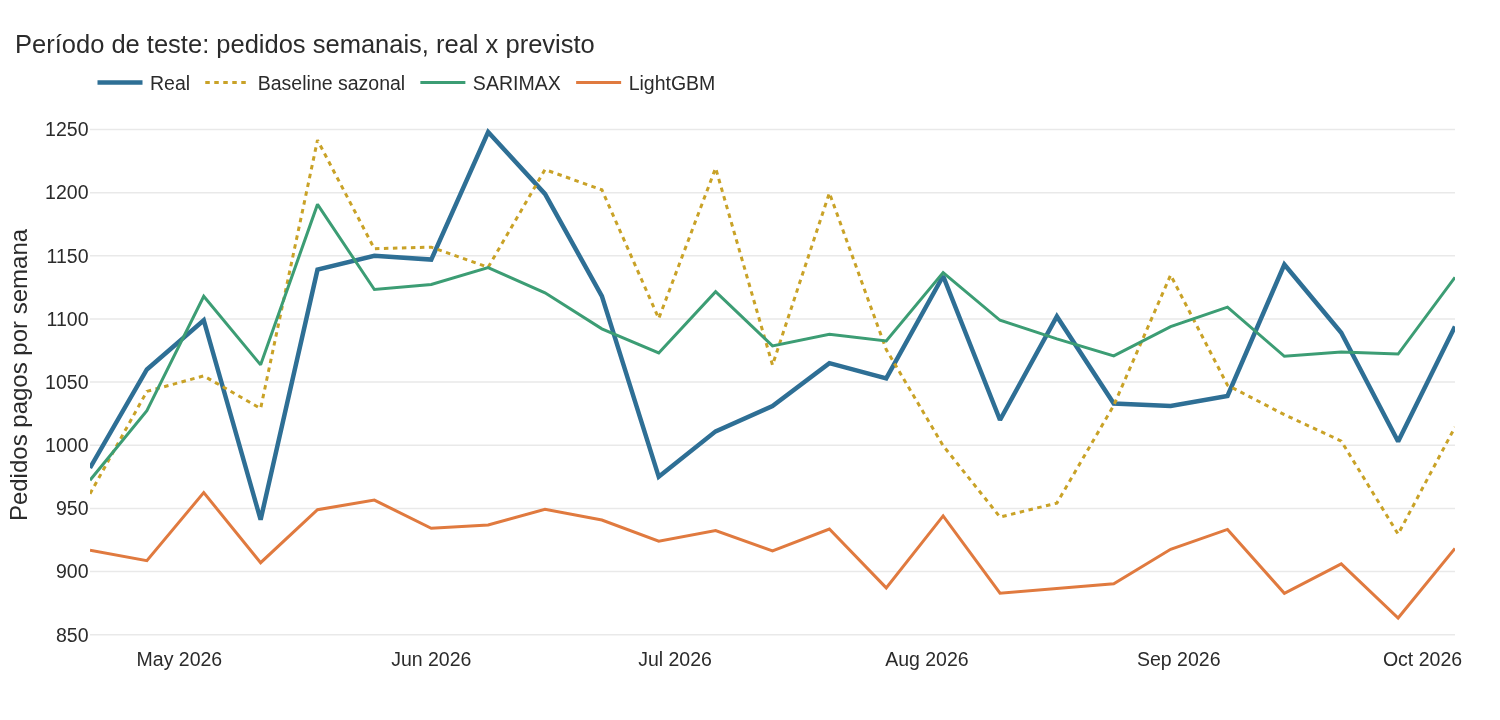

In [7]:
fig = go.Figure()
sem = lambda s: s.resample("W-MON", label="left", closed="left").sum().iloc[1:-1]
fig.add_scatter(x=sem(y_te).index, y=sem(y_te), name="Real", line=dict(color=COR_REAL, width=3))
for (nome, p), cor in zip(resultados.items(), [CORES[5], CORES[2], COR_PREVISTO]):
    fig.add_scatter(x=sem(p).index, y=sem(p), name=nome.split(" (")[0].split(" +")[0], line=dict(color=cor, dash="dot" if "Base" in nome else "solid"))
fig.update_layout(title="Período de teste: pedidos semanais, real x previsto", yaxis_title="Pedidos pagos por semana")
fig.show()

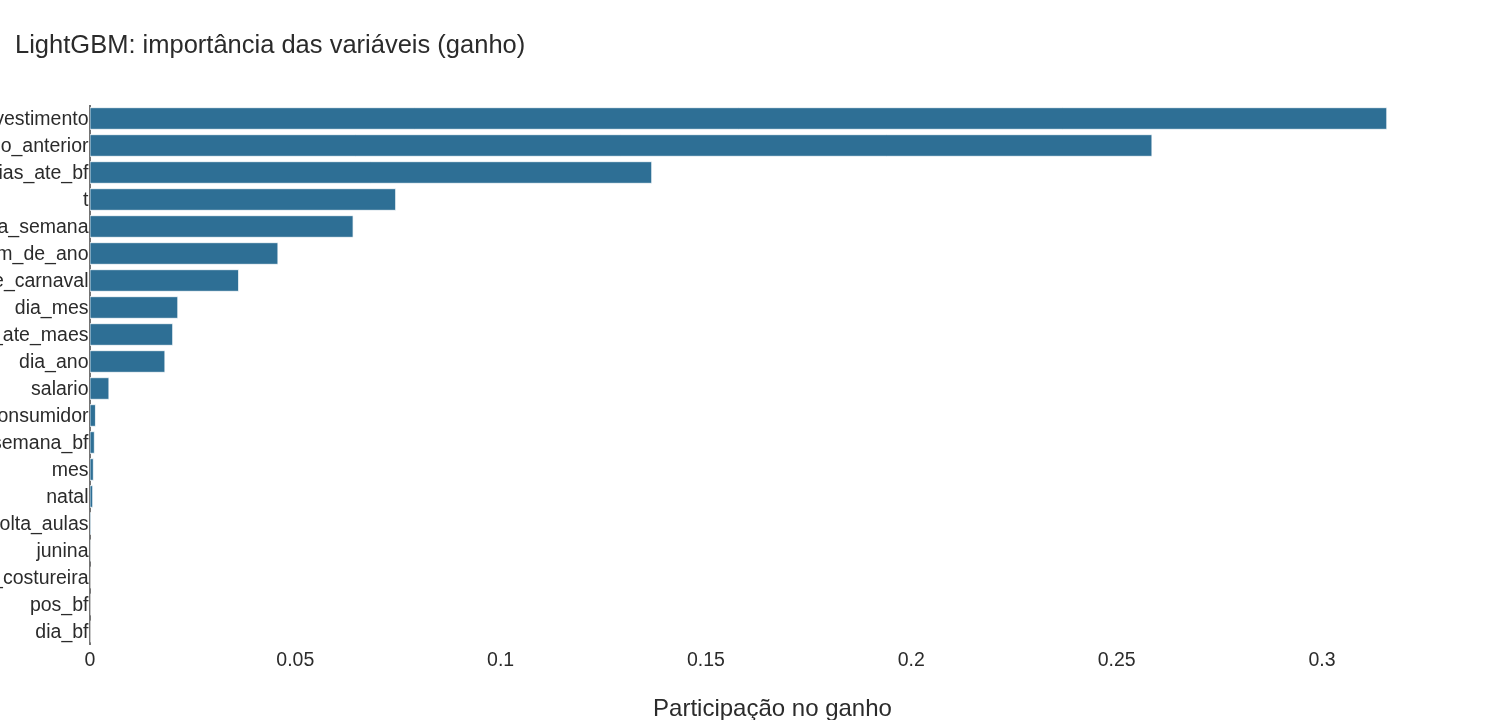

In [8]:
imp = pd.Series(m_lgb.feature_importance("gain"), index=feat).sort_values()
imp = imp / imp.sum()
fig = px.bar(x=imp.values, y=imp.index, orientation="h", title="LightGBM: importância das variáveis (ganho)",
             labels={"x": "Participação no ganho", "y": ""})
fig.update_traces(marker_color=COR_REAL)
fig.show()

## Forecast for the next 90 days (includes Black Friday 2026)

Model retrained on the full history. Future spend follows the plan: the average of the last 28 days, with +60% in Black Friday week. The forecast and the 80% interval come from SARIMAX, the best model in the test.

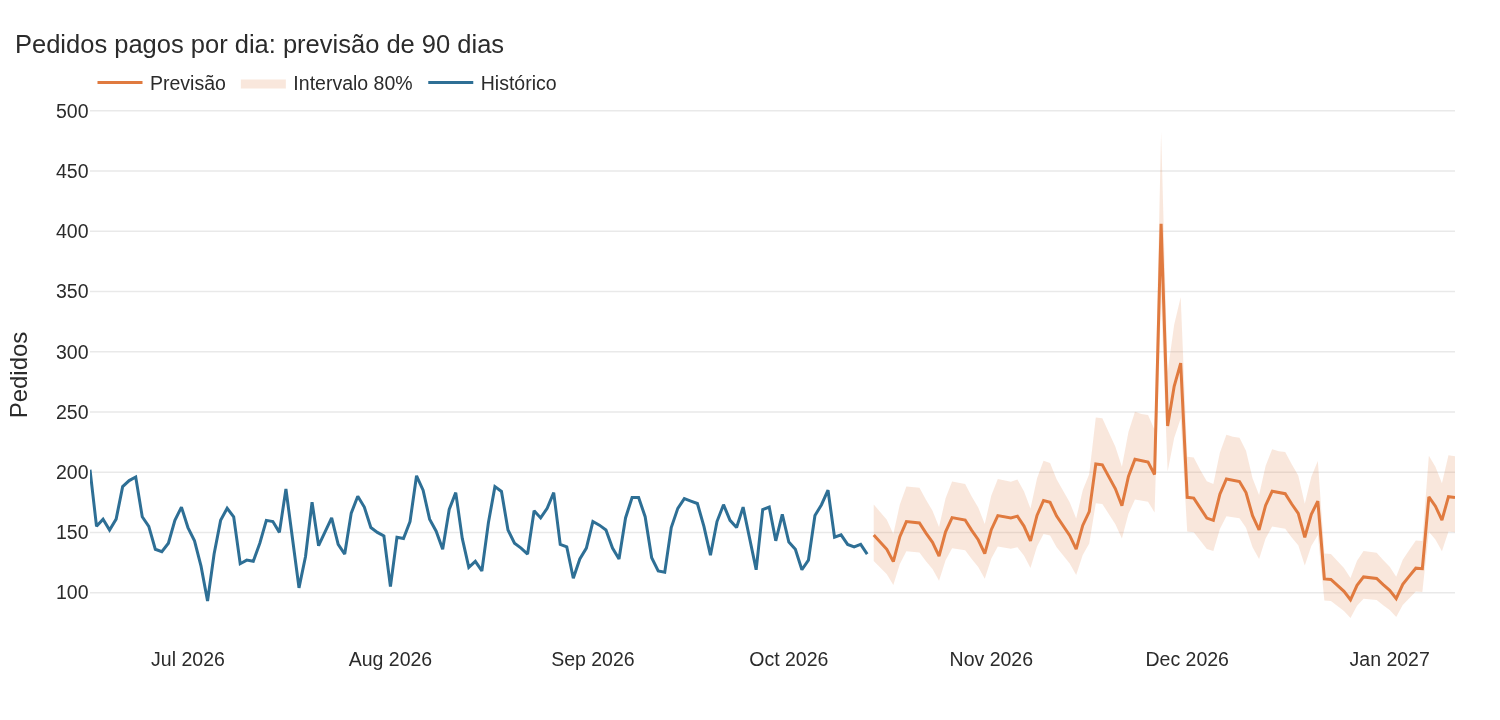

,pedidos_previstos,receita_prevista_R$
10/2026 (a partir de 14/10),2656.0,879000.0
11/2026,5739.0,1898000.0
12/2026,4730.0,1565000.0
01/2027 (até 11/01),1528.0,505000.0


In [9]:
futuro = pd.date_range(kpi.index[-1] + pd.Timedelta(days=1), periods=90, freq="D")
inv_plano = pd.Series(kpi["investimento"].iloc[-28:].mean(), index=futuro)
inv_plano[(futuro >= BF[-1] - pd.Timedelta(days=10)) & (futuro <= BF[-1] + pd.Timedelta(days=3))] *= 1.6
Xf = calendario(futuro, inv_plano)
Xf["pedidos_ano_anterior"] = kpi["pedidos"].reindex(futuro - pd.Timedelta(days=364)).values

# SARIMAX, o melhor modelo no teste, reajustado com todo o histórico
mod_full = sm.tsa.SARIMAX(np.log1p(y_all.values), exog=ex.values, **SARIMAX_KW).fit(disp=False, maxiter=200)
fc = mod_full.get_forecast(len(futuro), exog=exogenas(Xf).values)
ic = fc.conf_int(alpha=0.2)  # intervalo de 80%, na escala log
# expm1 do valor previsto no log é a mediana; serve de previsão pontual (conservadora em picos)
prev = pd.Series(np.expm1(fc.predicted_mean), index=futuro)
quant = {0.1: pd.Series(np.expm1(ic[:, 0]), index=futuro), 0.9: pd.Series(np.expm1(ic[:, 1]), index=futuro)}

hist = kpi["pedidos"].iloc[-120:]
fig = go.Figure()
fig.add_scatter(x=hist.index, y=hist, name="Histórico", line=dict(color=COR_REAL))
fig.add_scatter(x=futuro, y=quant[0.9], line=dict(width=0), showlegend=False, hoverinfo="skip")
fig.add_scatter(x=futuro, y=quant[0.1], fill="tonexty", fillcolor="rgba(224,122,63,0.18)", line=dict(width=0), name="Intervalo 80%")
fig.add_scatter(x=futuro, y=prev, name="Previsão", line=dict(color=COR_PREVISTO, width=2))
fig.update_layout(title="Pedidos pagos por dia: previsão de 90 dias", yaxis_title="Pedidos")
fig.show()

ticket = (kpi["receita"].iloc[-90:].sum() / kpi["pedidos"].iloc[-90:].sum())
mes = prev.resample("MS").sum()
resumo = pd.DataFrame({"pedidos_previstos": mes.round(0), "receita_prevista_R$": (mes * ticket).round(-3)})
resumo.index = [f"{d:%m/%Y}" + (" (a partir de 14/10)" if d.month == 10 else " (até 11/01)" if d.month == 1 else "") for d in resumo.index]
resumo

## Censored demand: what stockouts hide

When a SKU hits zero, the sale does not happen and the sales series **underestimates real demand**. A SKU-level forecasting model trained on sales alone learns that error. `estoque_diario.demanda_perdida` records the meters customers tried to buy with no stock available.

In [10]:
rup = sql("""
SELECT DATE_FORMAT(ed.data, '%Y-%m-01') AS mes, fam.nome AS familia, cat.nome AS subcategoria,
       SUM(ed.saidas * v.metros_por_unidade) AS metros_vendidos,
       SUM(ed.demanda_perdida * v.metros_por_unidade) AS metros_perdidos,
       AVG(ed.em_ruptura) AS pct_ruptura
FROM estoque_diario ed
JOIN variantes v ON v.variante_id = ed.variante_id
JOIN produtos p ON p.produto_id = v.produto_id
JOIN categorias cat ON cat.categoria_id = p.categoria_id
JOIN categorias fam ON fam.categoria_id = cat.categoria_pai_id
GROUP BY 1, 2, 3""")
rup["mes"] = pd.to_datetime(rup["mes"])
sub = rup.groupby("subcategoria")[["metros_vendidos", "metros_perdidos"]].sum()
sub["perda_pct"] = sub.metros_perdidos / (sub.metros_vendidos + sub.metros_perdidos)
print(f"Demanda perdida total: {rup.metros_perdidos.sum():,.0f} m "
      f"({rup.metros_perdidos.sum() / (rup.metros_vendidos.sum() + rup.metros_perdidos.sum()):.1%} da demanda)")
sub.sort_values("perda_pct", ascending=False).head(8).style.format({"metros_vendidos": "{:,.0f}", "metros_perdidos": "{:,.0f}", "perda_pct": "{:.1%}"})

Demanda perdida total: 176,804 m (15.3% da demanda)


,metros_vendidos,metros_perdidos,perda_pct
subcategoria,,,
Chita,"33,818","12,912",27.6%
Malha 100% Algodão,"16,265","3,919",19.4%
Viscolinho,"77,611","16,908",17.9%
Viscose Estampada,"65,956","13,968",17.5%
Linho Misto,"93,372","18,238",16.3%
Malha PV,"42,581","8,010",15.8%
Jeans,"62,343","11,462",15.5%
Crepe,"72,980","12,727",14.8%


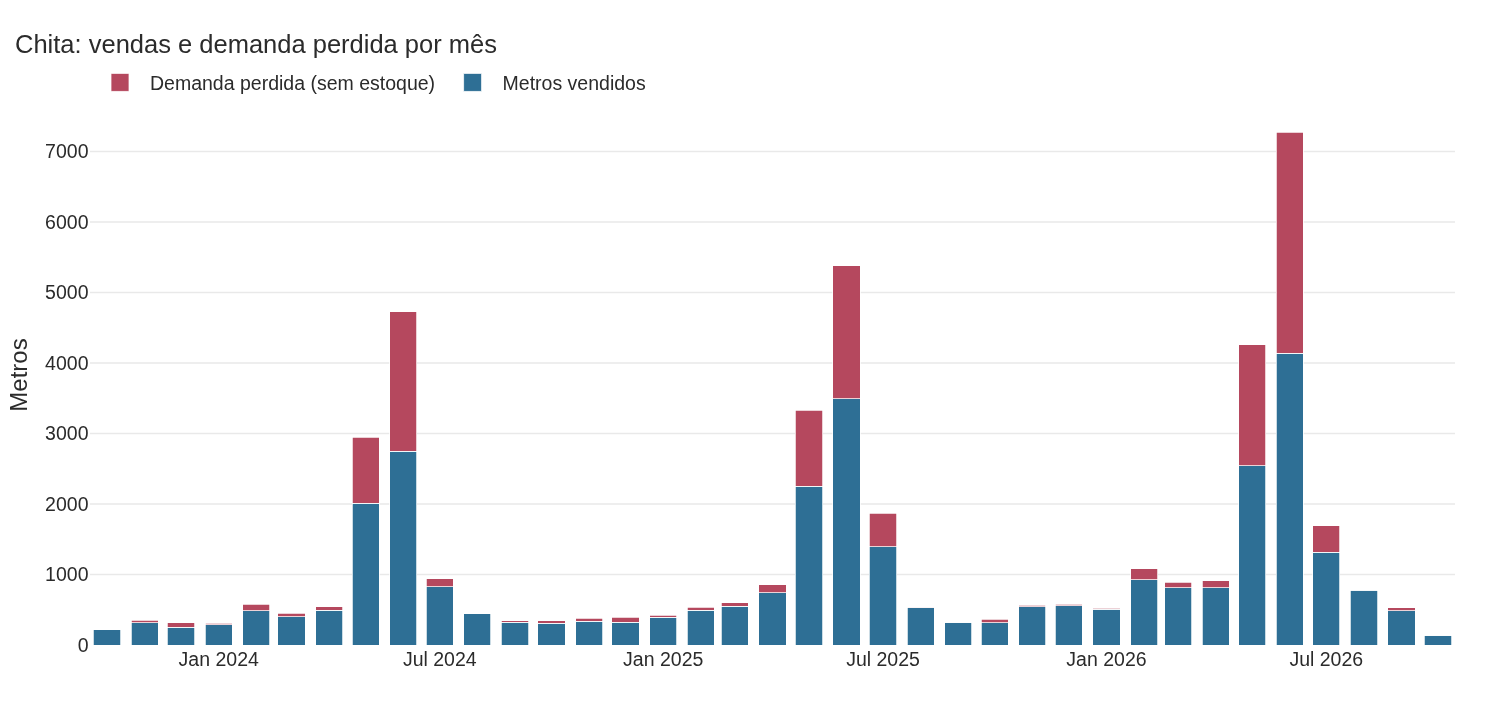

In [11]:
chita = rup[rup.subcategoria == "Chita"].set_index("mes").sort_index()
fig = go.Figure()
fig.add_bar(x=chita.index, y=chita.metros_vendidos, name="Metros vendidos", marker_color=COR_REAL)
fig.add_bar(x=chita.index, y=chita.metros_perdidos, name="Demanda perdida (sem estoque)", marker_color=COR_DESTAQUE)
fig.update_layout(barmode="stack", title="Chita: vendas e demanda perdida por mês", yaxis_title="Metros")
fig.show()

In [12]:
# números citados nas conclusões
melhor = tabela["WAPE diário"].idxmin()
bf_dia = prev[BF[-1]]
print(f"Melhor modelo no teste: {melhor} | WAPE diário {tabela.loc[melhor, 'WAPE diário']:.1%} | "
      f"WAPE semanal {tabela.loc[melhor, 'WAPE semanal']:.1%} | erro no total {tabela.loc[melhor, 'Erro no total do período']:+.1%}")
print(f"Baseline: WAPE diário {tabela.iloc[0]['WAPE diário']:.1%}")
print(f"Previsão para a Black Friday ({BF[-1].date()}): {bf_dia:,.0f} pedidos "
      f"(P10 {quant[0.1][BF[-1]]:,.0f} - P90 {quant[0.9][BF[-1]]:,.0f}); média diária recente {kpi.pedidos.iloc[-28:].mean():,.0f}")
pico = chita.loc[chita.index.month.isin([5, 6])]
print(f"Chita em maio-junho: {pico.metros_perdidos.sum() / (pico.metros_vendidos.sum() + pico.metros_perdidos.sum()):.1%} da demanda perdida")

Melhor modelo no teste: SARIMAX (log) + calendário | WAPE diário 9.6% | WAPE semanal 4.7% | erro no total +1.8%
Baseline: WAPE diário 13.4%
Previsão para a Black Friday (2026-11-27): 406 pedidos (P10 342 - P90 482); média diária recente 152
Chita em maio-junho: 38.5% da demanda perdida


## Business conclusions

1. **SARIMAX with calendar features is the model to use:** 9.6% daily and 4.7% weekly error over the 6 test months, against 13.4% for the "previous year x growth" baseline. LightGBM lost to the baseline (it underestimated by 14%): with only ~3 years of daily data, a statistical model with explicit seasonality generalizes better.
2. **Black Friday 2026 (Nov 27): ~406 orders on the day** (80% chance between 342 and 482), against 428 in 2025 and a recent average of 152 per day. Fulfillment and customer service need reinforcement for almost 3x the normal volume, and the peak extends through the weekend and Cyber Monday.
3. **November should close with ~5.7k orders and R$ 1.9 million** (+16% over Nov/2025), and December with ~4.7k orders and R$ 1.6 million, dropping sharply after the 22nd.
4. **Stockouts hide 15% of demand.** That is 177k meters customers tried to buy that were not available. Chita leads (28% loss; 39% in May-June, during the June festivals). SKU forecasts trained on sales alone inherit that bias: correct for lost demand before planning purchases, especially chita before May.